# Notebook 3 — Baseline ML Models (R3)
Rice Variety Classification | F20DL 2026/2027

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay

df = pd.read_csv('../data/tabular/rice_cammeo_osmancik.csv')
feature_names = [c for c in df.columns if c != 'Class']
X = df[feature_names].values
le = LabelEncoder()
y = le.fit_transform(df['Class'])
CLASS_NAMES = list(le.classes_)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

CV = 5  # cross-validation folds used in GridSearchCV
results = {}
print(f"Train: {len(X_train)}  Test: {len(X_test)}  GridSearchCV folds: {CV}")

Train: 3048  Test: 762  GridSearchCV folds: 5


## 1. Logistic Regression

In [2]:
param_grid_lr = {'C': [0.01, 0.1, 1, 10, 100], 'solver': ['lbfgs', 'liblinear']}
gs_lr = GridSearchCV(LogisticRegression(max_iter=2000, random_state=42), param_grid_lr, cv=CV, scoring='f1_weighted', n_jobs=-1)
gs_lr.fit(X_train_sc, y_train)
lr = gs_lr.best_estimator_
print(f"Best params: {gs_lr.best_params_}  CV F1: {gs_lr.best_score_:.4f}")

y_pred_lr = lr.predict(X_test_sc)
results['Logistic Regression'] = {
    'Accuracy':  accuracy_score(y_test, y_pred_lr),
    'Precision': precision_score(y_test, y_pred_lr, average='weighted'),
    'Recall':    recall_score(y_test, y_pred_lr, average='weighted'),
    'F1':        f1_score(y_test, y_pred_lr, average='weighted'),
}
print(classification_report(y_test, y_pred_lr, target_names=CLASS_NAMES))

Best params: {'C': 100, 'solver': 'lbfgs'}  CV F1: 0.9353
              precision    recall  f1-score   support

      Cammeo       0.93      0.88      0.90       326
    Osmancik       0.91      0.95      0.93       436

    accuracy                           0.92       762
   macro avg       0.92      0.91      0.92       762
weighted avg       0.92      0.92      0.92       762



## 2. k-Nearest Neighbours

In [3]:
param_grid_knn = {'n_neighbors': [3, 5, 7, 11, 15, 21], 'weights': ['uniform', 'distance'], 'metric': ['euclidean', 'manhattan']}
gs_knn = GridSearchCV(KNeighborsClassifier(), param_grid_knn, cv=CV, scoring='f1_weighted', n_jobs=-1)
gs_knn.fit(X_train_sc, y_train)
knn = gs_knn.best_estimator_
print(f"Best params: {gs_knn.best_params_}  CV F1: {gs_knn.best_score_:.4f}")

y_pred_knn = knn.predict(X_test_sc)
results['kNN'] = {
    'Accuracy':  accuracy_score(y_test, y_pred_knn),
    'Precision': precision_score(y_test, y_pred_knn, average='weighted'),
    'Recall':    recall_score(y_test, y_pred_knn, average='weighted'),
    'F1':        f1_score(y_test, y_pred_knn, average='weighted'),
}
print(classification_report(y_test, y_pred_knn, target_names=CLASS_NAMES))

Best params: {'metric': 'euclidean', 'n_neighbors': 11, 'weights': 'uniform'}  CV F1: 0.9301
              precision    recall  f1-score   support

      Cammeo       0.91      0.89      0.90       326
    Osmancik       0.92      0.93      0.92       436

    accuracy                           0.91       762
   macro avg       0.91      0.91      0.91       762
weighted avg       0.91      0.91      0.91       762



## 3. Random Forest

In [4]:
param_grid_rf = {'n_estimators': [100, 200], 'max_depth': [None, 10, 20], 'min_samples_split': [2, 5], 'max_features': ['sqrt', 'log2']}
gs_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_rf, cv=CV, scoring='f1_weighted', n_jobs=-1)
gs_rf.fit(X_train, y_train)
rf = gs_rf.best_estimator_
print(f"Best params: {gs_rf.best_params_}  CV F1: {gs_rf.best_score_:.4f}")

y_pred_rf = rf.predict(X_test)
results['Random Forest'] = {
    'Accuracy':  accuracy_score(y_test, y_pred_rf),
    'Precision': precision_score(y_test, y_pred_rf, average='weighted'),
    'Recall':    recall_score(y_test, y_pred_rf, average='weighted'),
    'F1':        f1_score(y_test, y_pred_rf, average='weighted'),
}
print(classification_report(y_test, y_pred_rf, target_names=CLASS_NAMES))

Best params: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_split': 5, 'n_estimators': 200}  CV F1: 0.9275
              precision    recall  f1-score   support

      Cammeo       0.93      0.87      0.90       326
    Osmancik       0.91      0.95      0.93       436

    accuracy                           0.92       762
   macro avg       0.92      0.91      0.91       762
weighted avg       0.92      0.92      0.92       762



## 4. Model Comparison Summary

                     Accuracy  Precision  Recall      F1
Logistic Regression    0.9186     0.9189  0.9186  0.9183
Random Forest          0.9160     0.9164  0.9160  0.9157
kNN                    0.9121     0.9120  0.9121  0.9119


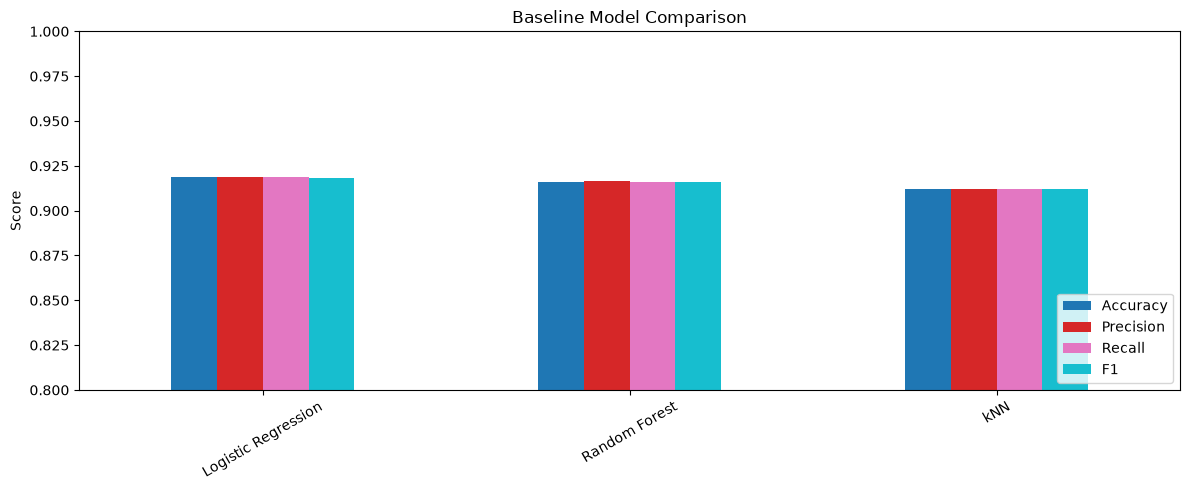

In [5]:
summary = pd.DataFrame(results).T.round(4)
summary = summary.sort_values('F1', ascending=False)
print(summary.to_string())
summary.to_csv('../results/baseline_comparison.csv')

ax = summary[['Accuracy', 'Precision', 'Recall', 'F1']].plot(
    kind='bar', figsize=(12, 5), ylim=(0.8, 1.0), rot=30, colormap='tab10'
)
ax.set_title('Baseline Model Comparison')
ax.set_ylabel('Score')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('../results/baseline_comparison.png', dpi=100)
plt.show()

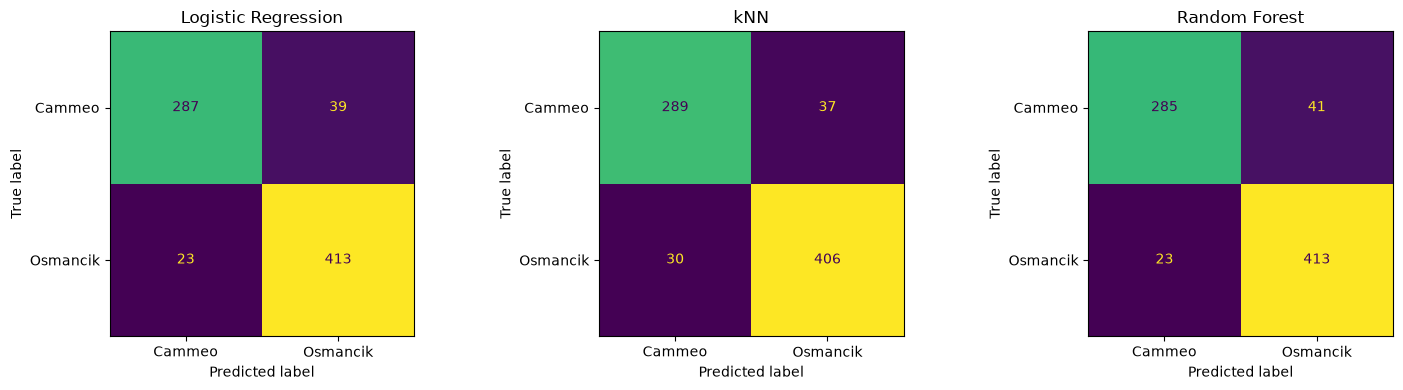

In [6]:
# Confusion matrices for all 3 models
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, preds) in zip(axes, [
    ('Logistic Regression', y_pred_lr),
    ('kNN', y_pred_knn),
    ('Random Forest', y_pred_rf),
]):
    ConfusionMatrixDisplay.from_predictions(y_test, preds, display_labels=CLASS_NAMES, ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig('../results/confusion_matrices.png', dpi=100)
plt.show()